In [18]:
import pandas as pd
import matplotlib.pyplot as plt

The aim of this prject is to find the following: Which products and regions are actually driving the business, and is there anything suspicious about returns or customer ratings?

# Boiler Plate

In [19]:
df = pd.read_csv("ecommerce_sales_real_world_practice.csv")

df["Date"] = pd.to_datetime(df["Date"])
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             24 non-null     datetime64[us]
 1   Product          24 non-null     str           
 2   Category         24 non-null     str           
 3   Units_Sold       24 non-null     int64         
 4   Unit_Price_USD   24 non-null     int64         
 5   Revenue_USD      24 non-null     int64         
 6   Region           24 non-null     str           
 7   Customer_Rating  24 non-null     float64       
 8   Returned_Units   24 non-null     int64         
dtypes: datetime64[us](1), float64(1), int64(4), str(3)
memory usage: 1.8 KB
None
                      Date  Units_Sold  Unit_Price_USD   Revenue_USD  \
count                   24   24.000000       24.000000     24.000000   
mean   2026-03-30 00:00:00   31.458333      469.791667  12611.458333   
min    2026-01-05 00:00:00  

# Product Performance

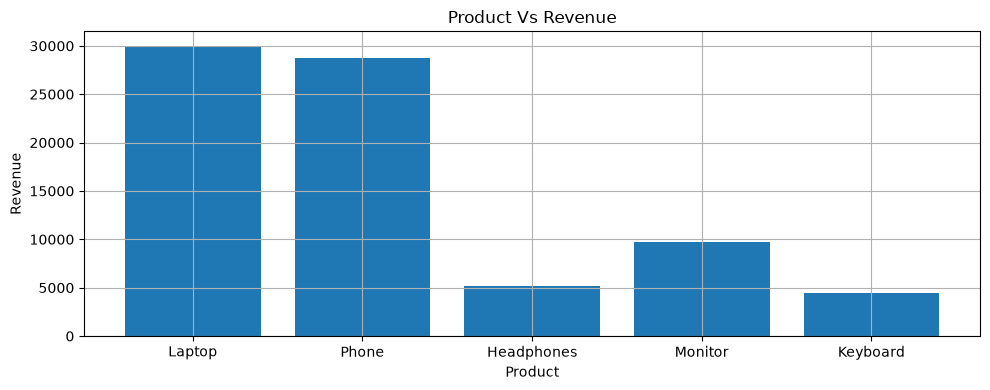

In [20]:
product_summary = df.groupby("Product").agg({
    "Units_Sold": "sum",
    "Revenue_USD": "sum"
})

plt.figure(figsize=(10, 4))
plt.bar(df["Product"], df["Revenue_USD"])
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.title("Product Vs Revenue")
plt.grid()
plt.tight_layout()

# Revenue Vs Units Sold

C:\Users\HP\AppData\Local\Temp\ipykernel_16628\518266314.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


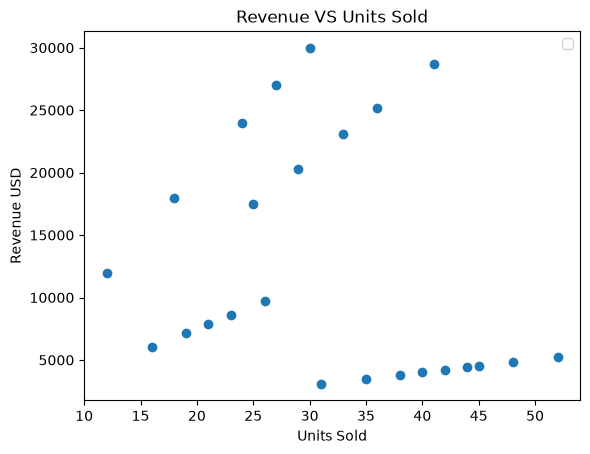

In [21]:
for product in df["Product"].unique():
    product_data = df[df["Product"] == product]

plt.scatter(df["Units_Sold"], df["Revenue_USD"])
plt.xlabel("Units Sold")
plt.ylabel("Revenue USD")
plt.title("Revenue VS Units Sold")
plt.legend()

plt.show()

# Returns Analysis 

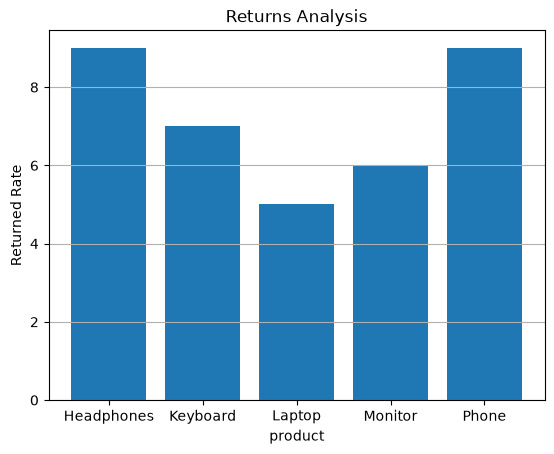

In [30]:
returns = df.groupby("Product")["Returned_Units"].sum()
summary = df.groupby("Product").agg({
    "Units_Sold": "sum",
    "Returned_Units": "sum"
})

summary["Returned_Rate"] = (summary["Returned_Units"] / summary["Units_Sold"] * 100)

plt.bar(returns.index,
        returns.values)
plt.xlabel("product")
plt.ylabel("Returned Rate")
plt.title("Returns Analysis")
plt.grid(axis='y')

plt.show()

# Customer Ratings

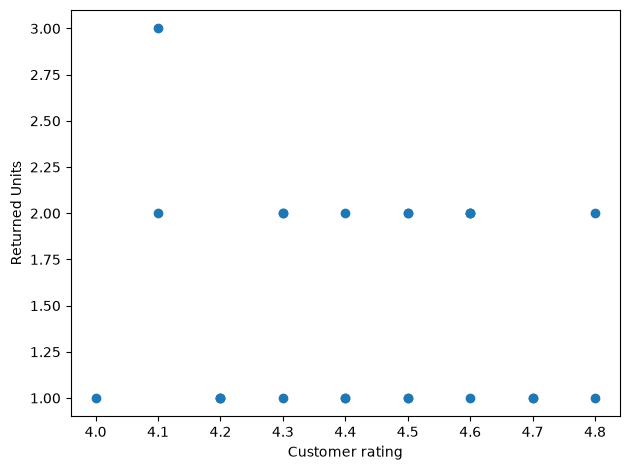

In [23]:
plt.scatter(df['Customer_Rating'], df["Returned_Units"])
plt.xlabel("Customer rating")
plt.ylabel("Returned Units")
plt.tight_layout()

plt.show()

# Dashboard 

Text(0.5, 1.0, 'Rating VS Return')

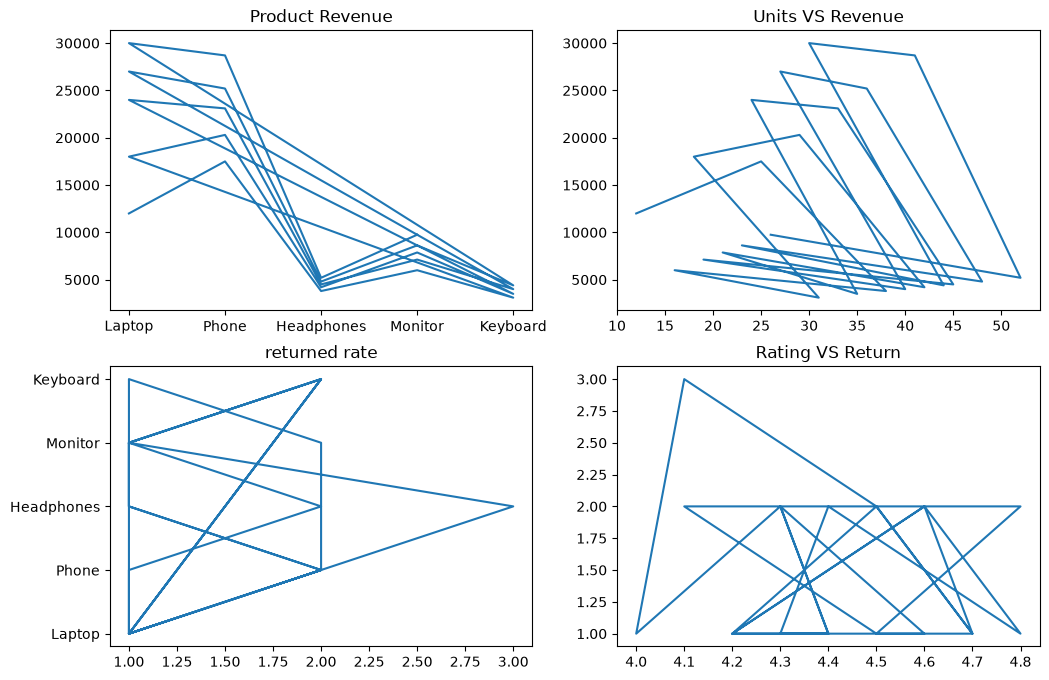

In [29]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

ax[0, 0].plot(df["Product"], df["Revenue_USD"])
ax[0,0].set_title("Product Revenue")

ax[0, 1].plot(df["Units_Sold"], df["Revenue_USD"])
ax[0, 1].set_title("Units VS Revenue")

ax[1, 0].plot(df["Returned_Units"], df["Product"])
ax[1, 0].set_title("returned rate")

ax[1, 1].plot(df["Customer_Rating"], df["Returned_Units"])
ax[1, 1].set_title("Rating VS Return")